# **Email spam Detection with Machine Learning**


![](https://i.imgur.com/1RSZNsh.gif)




# Lecture 1 practice:  Spam Email Detection Project

**Project Name:** "Spam vs Ham Email Classifier"  
**Instructor:** M. Imtiaz
### Introduction:

- Spam emails are unwanted messages sent to many recipients, often containing phishing attempts, scams, or irrelevant content.
- The goal of this project is to build a **Python-based machine learning system** to detect and classify emails as **Spam** or **Ham (legitimate email)**.
- Benefits of this project:
  - Helps keep inboxes clean and secure
  - Identifies potentially harmful emails automatically
- We will follow a standard **data science workflow**:
  1. Data acquisition
  2. Data preprocessing
  3. Feature extraction
  4. Model training
  5. Model evaluation
  6. Making predictions on new emails
- **Outcome:** A functional email spam detector that classifies emails and provides prediction confidence.



In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
uciml_sms_spam_collection_dataset_path = kagglehub.dataset_download('uciml/sms-spam-collection-dataset')

print('Data source import complete.')


Using Colab cache for faster access to the 'sms-spam-collection-dataset' dataset.
Data source import complete.


# **Import Libraries**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np # Used for numerical operations, especially with arrays.
import pandas as pd # Essential for data manipulation and analysis, providing DataFrames.
import matplotlib.pyplot as plt # For creating static, interactive, and animated visualizations.
import seaborn as sns # A high-level library for drawing attractive and informative statistical graphics.
from sklearn.model_selection import train_test_split # To split data into training and testing sets.
from sklearn.feature_extraction.text import TfidfVectorizer # To convert text data into numerical TF-IDF features.
from sklearn.linear_model import LogisticRegression # The classification model used for spam detection.
from sklearn.metrics import accuracy_score , confusion_matrix # For evaluating model performance.
from sklearn.metrics import classification_report # For a detailed report on classification metrics.

In [ ]:
import nltk # Natural Language Toolkit, a library for working with human language data.
from nltk.corpus import stopwords # Imports a list of common words (stopwords) that are often removed in text processing.
from collections import Counter # A dictionary subclass for counting hashable objects, useful for frequency analysis.

# **Load the dataset**

In [ ]:

# Load the dataset
df = pd.read_csv("/kaggle/input/sms-spam-collection-dataset/spam.csv", encoding="ISO-8859-1")

# Display the first few rows of the dataset
df.head(10)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's n...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. ...,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnamin...,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have...,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitle...,NaN,NaN,NaN


# **Exploring the Dataset**
### Step: Remove Unnecessary Columns
- Drops columns that do not contain useful information
- Cleans the dataset by removing auto-generated or empty columns
- Simplifies the DataFrame for further analysis and processing


In [ ]:
# Drop unnecessary columns from the DataFrame
column_to_remove = ['Unnamed: 2','Unnamed: 3','Unnamed: 4']
df = df.drop(column_to_remove, axis=1)

In [ ]:
df

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


### Step: Check Dataset Dimensions
- Displays the number of rows and columns in the DataFrame

In [ ]:
df.shape

(5572, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [ ]:
df.describe()

,v1,v2
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [ ]:
df[df.duplicated()]

,v1,v2
102,ham,As per your request 'Melle Melle (Oru Minnamin...
153,ham,As per your request 'Melle Melle (Oru Minnamin...
206,ham,"As I entered my cabin my PA said, '' Happy B'd..."
222,ham,"Sorry, I'll call later"
325,ham,No calls..messages..missed calls
...,...,...
5524,spam,You are awarded a SiPix Digital Camera! call 0...
5535,ham,"I know you are thinkin malaria. But relax, chi..."
5539,ham,Just sleeping..and surfing
5553,ham,Hahaha..use your brain dear


In [ ]:
df = df.drop_duplicates()
df

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [ ]:
df["v1"].value_counts()

,count
v1,
ham,4516
spam,653


# **Data Visualisation**

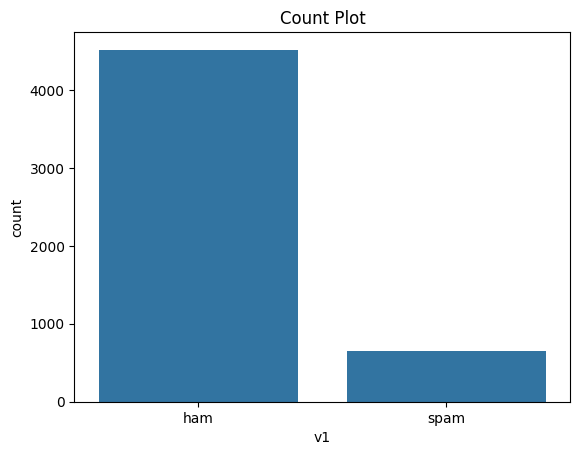

In [ ]:
sns.countplot(data=df, x='v1')
plt.xlabel('v1')
plt.ylabel('count')
plt.title('Count Plot')
plt.show()

# **Data Preprocessing**

In [ ]:
# Convert the "Category" column values to numerical representation (0 for "spam" and 1 for "ham")

df.loc[df["v1"] == "spam", "Category"] = 0
df.loc[df["v1"] == "ham", "Category"] = 1

df.head()

/tmp/ipython-input-521347544.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[df["v1"] == "spam", "Category"] = 0


,v1,v2,Category
0,ham,"Go until jurong point, crazy.. Available only ...",1.0
1,ham,Ok lar... Joking wif u oni...,1.0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,0.0
3,ham,U dun say so early hor... U c already then say...,1.0
4,ham,"Nah I don't think he goes to usf, he lives aro...",1.0


In [ ]:
# Separate the feature (v2) and target (category) data
X=df['v2']
y=df['Category']


In [ ]:
X

,v2
0,"Go until jurong point, crazy.. Available only ..."
1,Ok lar... Joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...
3,U dun say so early hor... U c already then say...
4,"Nah I don't think he goes to usf, he lives aro..."
...,...
5567,This is the 2nd time we have tried 2 contact u...
5568,Will Ì_ b going to esplanade fr home?
5569,"Pity, * was in mood for that. So...any other s..."
5570,The guy did some bitching but I acted like i'd...


In [ ]:
y

,Category
0,1.0
1,1.0
2,0.0
3,1.0
4,1.0
...,...
5567,0.0
5568,1.0
5569,1.0
5570,1.0


# **Split Data to Train and Test Data**

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

# **Feature Extraction - TF-IDF**

In [ ]:
#Create a TF-IDF vectorizer to convert text messages into numerical feature
feature_extraction = TfidfVectorizer(min_df=1, stop_words='english',lowercase=True)
X_train_features = feature_extraction.fit_transform(X_train)
X_test_features = feature_extraction.transform(X_test)

y_train = y_train.astype(int)
y_test = y_test.astype(int)


# **Model Training**

In [ ]:
model = LogisticRegression()
model.fit(X_train_features,y_train)

LogisticRegression()

# **Model Evaluation**

- Generates predictions on both training and test datasets
- Calculates accuracy to measure model performance
- Compares training and test accuracy to check for overfitting or underfitting
- Displays accuracy results for model evaluation


In [ ]:
# Model evaluation
prediction_on_training_data = model.predict(X_train_features)
accuracy_on_training_data = accuracy_score(y_train, prediction_on_training_data)

prediction_on_test_data = model.predict(X_test_features)
accuracy_on_test_data = accuracy_score(y_test, prediction_on_test_data)

# Print accuracy
print('Accuracy on training data: {} %'.format(accuracy_on_training_data * 100))
print('Accuracy on test data: {} %'.format(accuracy_on_test_data * 100))

Accuracy on training data: 96.32406287787182 %
Accuracy on test data: 96.0348162475822 %


# **Confusion Matrix Visualization**
- Computes the confusion matrix using actual and predicted labels
- Visualizes classification results using a heatmap
- Shows correct and incorrect predictions for each class
- Helps analyze model performance beyond accuracy

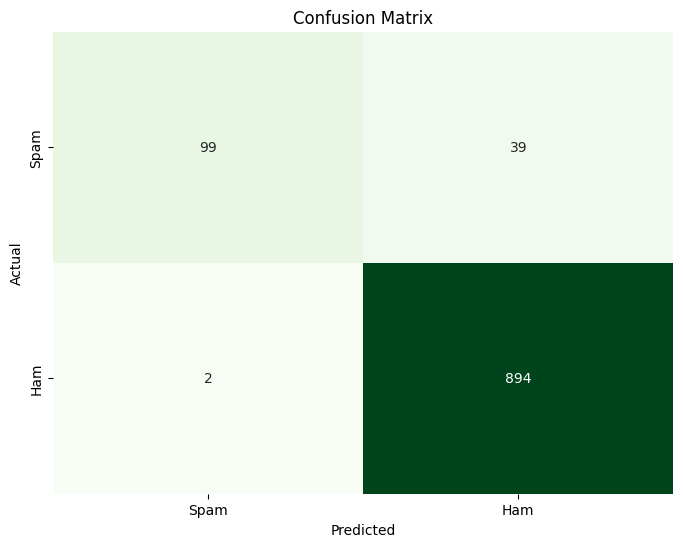

In [ ]:
# Confusion Matrix Visualization
conf_matrix = confusion_matrix(y_test, prediction_on_test_data)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=['Spam', 'Ham'], yticklabels=['Spam', 'Ham'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


# **Calculating and Displaying Error Metrics**
- Creates a detailed performance report for each class
- Displays precision, recall, F1-score, and support values
- Helps evaluate how well the model performs on Spam and Ham classes
- Provides deeper insight beyond overall accuracy

In [ ]:
# Classification report
classification_rep = classification_report(y_test, prediction_on_test_data,target_names=['Spam', 'Ham'])
print("Classification Report:")
print(classification_rep)

Classification Report:
              precision    recall  f1-score   support

        Spam       0.98      0.72      0.83       138
         Ham       0.96      1.00      0.98       896

    accuracy                           0.96      1034
   macro avg       0.97      0.86      0.90      1034
weighted avg       0.96      0.96      0.96      1034



### Calculate Performance Metrics Manually
- Extracts True Positives, True Negatives, False Positives, and False Negatives from the confusion matrix
- Computes key evaluation metrics: accuracy, precision, recall, and specificity
- Provides a manual verification of model performance
- Helps understand classification behavior in detail


In [ ]:
# Metrics calculation
TP = conf_matrix[1, 1]
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
specificity = TN / (TN + FP)

print("Accuracy : ",accuracy)
print("Precision : ",precision)
print("Recall : ",recall)
print("Specificity : ",specificity)

Accuracy :  0.960348162475822
Precision :  0.9581993569131833
Recall :  0.9977678571428571
Specificity :  0.717391304347826


# **Make Predictions on New Input**


📩 Email Content:
 Dear John, I hope this email finds you well. Attached is the report you requested for our upcoming meeting. Please review it at your convenience

🔍 Prediction: Ham Mail ✅


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128683 (\N{NO ENTRY SIGN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


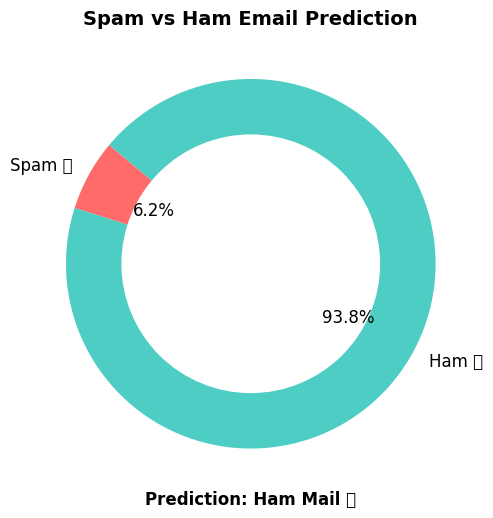

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------
# Step 1: Input Email
# -------------------------------
spam_email = "Congratulations! You've won a luxury vacation package worth $10,000! Click here to claim your prize now!"
ham_email = "Dear John, I hope this email finds you well. Attached is the report you requested for our upcoming meeting. Please review it at your convenience"

input_your_mail = ham_email


# -------------------------------
# Step 2: Feature Transformation
# -------------------------------
input_data_features = feature_extraction.transform([input_your_mail])


# -------------------------------
# Step 3: Prediction
# -------------------------------
prediction = model.predict(input_data_features)
prediction_prob = model.predict_proba(input_data_features)[0]


# -------------------------------
# Step 4: Result Label
# -------------------------------
labels = ['Spam 🚫', 'Ham ✅']
colors = ['#ff6b6b', '#4ecdc4']

result = "Ham Mail ✅" if prediction[0] == 1 else "Spam Mail 🚫"

print("📩 Email Content:\n", input_your_mail)
print("\n🔍 Prediction:", result)


# -------------------------------
# Step 5: Donut Chart Visualization
# -------------------------------
plt.figure(figsize=(6, 6))

wedges, texts, autotexts = plt.pie(
    prediction_prob,
    labels=labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 12}
)

# Create donut hole
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
plt.gca().add_artist(centre_circle)

# Title
plt.title("Spam vs Ham Email Prediction", fontsize=14, fontweight='bold')

# Highlight predicted class
plt.text(0, -1.3, f"Prediction: {result}",
         ha='center', fontsize=12, fontweight='bold')

plt.show()
